# Air Quality ML
Gradient descent, classification and neural network regression

University of Manchester COMP24112 coursework, 2024. Portfolio preparation: 22 October 2026.

This notebook preserves the completed historical implementation and saved aggregate results. It has **not been rerun**. Execution counts are cleared; plots and metric outputs are historical. The data and fitted model are excluded. Read [data instructions](../data/README.md) and [methodology/provenance notes](../docs/NOTES.md) before attempting execution.

The custom contribution is the NumPy linear-classifier implementation, manual evaluation and experiment orchestration added to teaching scaffolding. MLPRegressor, backpropagation, SGD, Adam, preprocessing and cross-validation are provided by scikit-learn. This is not a new model architecture or a clean benchmark.

The target is CO(GT), predicted from 11 other measurements. Classification treats CO(GT) > 4.5 as positive; regression predicts its numeric value. These are coursework task definitions, not a validated health-advice system.

## Data loading

The authorised local coursework workbook is required only for execution. Its sample-row output has been removed from this public copy.

In [ ]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import time
import sklearn.model_selection


notebook_start_time = time.time()

# Local data path: supports a kernel started in the package root or notebooks/.
from pathlib import Path
DATA_PATH = Path("data/sensor_data.xlsx") if Path("data").is_dir() else Path("../data/sensor_data.xlsx")
sensor_data_full = pd.read_excel(DATA_PATH)



## NumPy linear classifier

Historical batch updates accumulate contributions from samples with margin below one. The implementation is retained unchanged, including its objective mismatch: `c` weights regularisation, the bias is penalised, and logged cost is only summed hinge loss. See the notes for comparison with the intended objective.

In [ ]:
def linear_gd_train(data, labels, c=0.2, n_iters=200, learning_rate=0.001, random_state=None
          ):
    """

    data: training data
    labels: training labels (boolean)
    c: regularisation parameter
    n_iters: number of iterations
    learning_rate: learning rate for gradient descent

    Returns an array of cost and model weights per iteration.
    """
    # Set random seed for reproducibility if using random initialisation of weights (optional)
    rng = np.random.default_rng(seed=random_state)

    # Create design matrix and labels
    X = data
    y = labels
    X_tilde = np.concatenate((np.ones((X.shape[0], 1)), X), axis=-1)
    y = 2 * labels - 1

    # Weight initialisation: use e.g. rng.standard_normal() or all zeros
    w = rng.standard_normal(X_tilde.shape[1])

    # Initialise arrays to store weights and cost at each iteration
    w_all = np.zeros((n_iters, X_tilde.shape[1]))
    cost_all = np.zeros(n_iters)
    
    for i in range(n_iters):
        gradient = np.zeros(w.shape)
        cost = 0
        
        # Iterate over each data point
        for idx, x_i in enumerate(X_tilde):
            margin = y[idx] * np.dot(x_i, w)
            if margin < 1:
                # Update for misclassified points
                gradient -= y[idx] * x_i
                cost += 1 - margin
        # Regularization term gradient is added for all points
        gradient += 2 * c * w
        
        # Update weights
        w -= learning_rate * gradient
        
        # Store the cost and weights
        cost_all[i] = cost
        w_all[i] = w
    

    # Return model parameters.
    return cost_all, w_all


def linear_predict(data, w):
    """

    data: test data
    w: model weights

    Returns the predicted labels.
    """
    X_tilde = np.concatenate((np.ones((data.shape[0], 1)), data), axis=-1)
    

    y_pred_scores = np.dot(X_tilde, w)
    y_pred = y_pred_scores > 0
    
    return y_pred

## Classification preprocessing

The training split, mean imputation and standardisation below were supplied scaffolding. The split is stratified but has no fixed seed.

In [ ]:
from sklearn.impute import SimpleImputer

# Put a threshold on the labels to cast to binary: True if CO(GT) > 4.5, False otherwise
binary_targets = (sensor_data_full['CO(GT)'] > 4.5).to_numpy()
sensor_data = sensor_data_full.drop(columns=['CO(GT)']).to_numpy()

# Named _cls to keep our classification experiments distinct from regression
train_X_cls, test_X_cls, train_y_cls, test_y_cls = sklearn.model_selection.train_test_split(sensor_data, binary_targets, test_size=0.15, stratify=binary_targets)

# Impute missing values and standardise the data
imputer = SimpleImputer(missing_values=-999, strategy='mean')
scaler = sklearn.preprocessing.StandardScaler()

train_X_cls = imputer.fit_transform(train_X_cls)
train_X_cls = scaler.fit_transform(train_X_cls)

## Baseline evaluation

The manual positive-class F1 and accuracy calculations and the saved plot are preserved. **Historical error:** test preprocessing is refitted with `fit_transform` rather than reusing the training transforms. The plot's “Cost” label refers to unregularised hinge loss. Saved accuracy/F1 are observations from this flawed workflow.

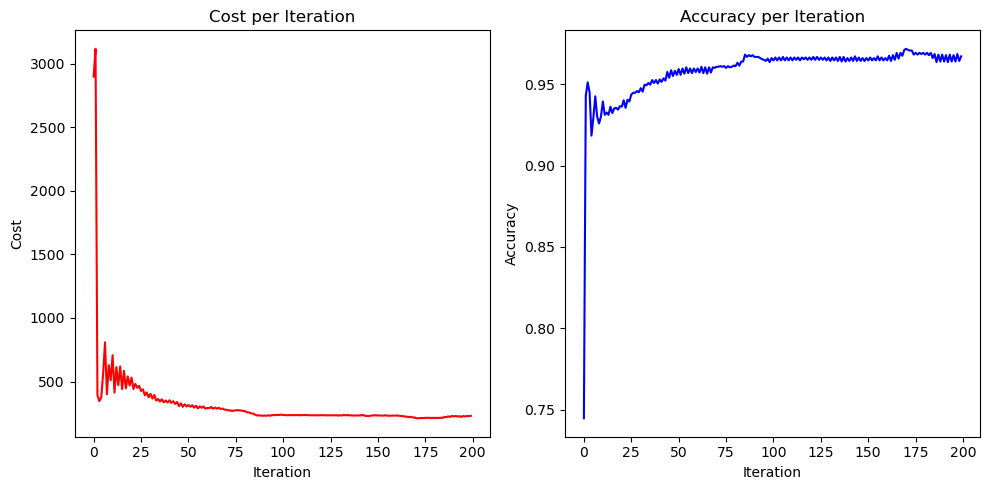

Accuracy on Test Set: 0.9597
F1 Score on Test Set: 0.6296


In [ ]:
# Train the model

costs, weights = linear_gd_train(train_X_cls, train_y_cls, c=0.2, n_iters=200, learning_rate=0.001, random_state=None)
final_weights = weights[-1]
#pred_training = linear_predict(train_X_cls, final_weights)
accuracies = []
for w in weights:
    pred_training = linear_predict(train_X_cls, w)
    accuracy = np.mean(train_y_cls == pred_training)
    accuracies.append(accuracy)

import matplotlib.pyplot as plt

# Plot for Cost
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)  # 1 row, 2 columns, 1st subplot
plt.plot(range(200), costs, color='red')
plt.title('Cost per Iteration')
plt.xlabel('Iteration')
plt.ylabel('Cost')

# Plot for Accuracy
plt.subplot(1, 2, 2)  # 1 row, 2 columns, 2nd subplot
plt.plot(range(200), accuracies, color='blue')
plt.title('Accuracy per Iteration')
plt.xlabel('Iteration')
plt.ylabel('Accuracy')

plt.tight_layout()
plt.show()


# Apply imputation to the test set
test_X_cls = imputer.fit_transform(test_X_cls)
test_X_cls = scaler.fit_transform(test_X_cls)
pred_test = linear_predict(test_X_cls, final_weights)

correct_predictions1 = (test_y_cls == pred_test).sum()
accuracy_test = correct_predictions1 /len(pred_test)
print(f"Accuracy on Test Set: {accuracy_test:.4f}") 

TP = ((test_y_cls == 1) & (pred_test == 1)).sum()
FP = ((test_y_cls == 0) & (pred_test == 1)).sum()
FN = ((test_y_cls == 1) & (pred_test == 0)).sum()

precision = TP / (TP + FP) if (TP + FP) > 0 else 0
recall = TP / (TP + FN) if (TP + FN) > 0 else 0
f1_score = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

print(f"F1 Score on Test Set: {f1_score:.4f}")


# Predict on test set, report accuracy and f1 score

## Learning-rate experiment

Four learning rates, 200 iterations each. Initial weights are unseeded. These single-run results differ from the earlier notebook and are not a controlled estimate of learning-rate effects.

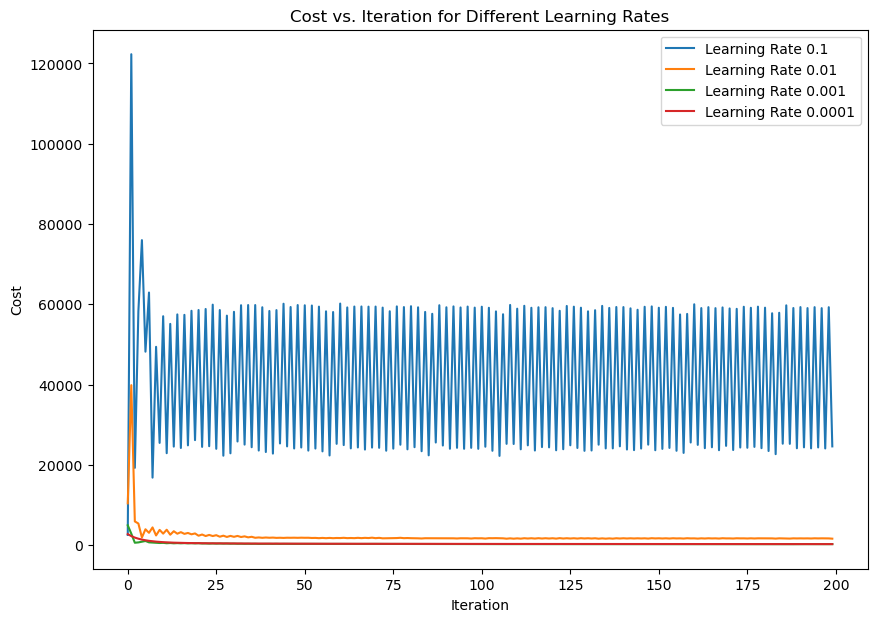

Test Metrics for Different Learning Rates:
Learning Rate 0.1: Accuracy = 0.9194, F1 Score = 0.0000
Learning Rate 0.01: Accuracy = 0.9456, F1 Score = 0.7158
Learning Rate 0.001: Accuracy = 0.9617, F1 Score = 0.6545
Learning Rate 0.0001: Accuracy = 0.9677, F1 Score = 0.7241


In [ ]:
learning_rates = [0.1, 0.01, 0.001, 0.0001]
training_results = {}
test_metrics = {}

# Train the model at each learning rate and evaluate
for rate in learning_rates:
    costs, weights = linear_gd_train(train_X_cls, train_y_cls, c=0.2, n_iters=200, learning_rate=rate, random_state=None)
    final_weights = weights[-1]
    pred_test = linear_predict(test_X_cls, final_weights)

    # Calculate Accuracy
    correct_predictions = (test_y_cls == pred_test).sum()
    total_predictions = len(pred_test)
    accuracy = correct_predictions / total_predictions

    # Calculate F1 Score
    TP = ((test_y_cls == 1) & (pred_test == 1)).sum()
    FP = ((test_y_cls == 0) & (pred_test == 1)).sum()
    FN = ((test_y_cls == 1) & (pred_test == 0)).sum()
    precision = TP / (TP + FP) if (TP + FP) > 0 else 0
    recall = TP / (TP + FN) if (TP + FN) > 0 else 0
    f1_score = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

    training_results[rate] = costs
    test_metrics[rate] = (accuracy, f1_score)

# Plotting Cost vs. Iteration for each Learning Rate
fig, ax = plt.subplots(figsize=(10, 7))
for rate, costs in training_results.items():
    ax.plot(costs, label=f'Learning Rate {rate}')
ax.set_xlabel('Iteration')
ax.set_ylabel('Cost')
ax.set_title('Cost vs. Iteration for Different Learning Rates')
ax.legend()
plt.show()

# Compare and print Test Metrics
print("Test Metrics for Different Learning Rates:")
for rate, metrics in test_metrics.items():
    accuracy, f1_score = metrics
    print(f"Learning Rate {rate}: Accuracy = {accuracy:.4f}, F1 Score = {f1_score:.4f}")

## MLP architecture selection

The architecture/activation search space came from teaching material. Training and evaluation use scikit-learn.

In [ ]:
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer


param_grid = [
    {   
        'hidden_layer_sizes': [(3,), (100,), (3, 3), (100, 100)],
        'activation': ['relu', 'logistic'],
    },
]

### Historical grid search and evaluation

**Historical limitations:** preprocessing is fitted before cross-validation, leaking validation-fold information. The printed “Standard Deviation of MSE” is spread across candidate mean CV scores, not fold uncertainty of the selected model. The held-out test set uses the training transforms here.

In [ ]:
# Redo split for regression
X = sensor_data_full.drop(columns='CO(GT)')
y = sensor_data_full['CO(GT)']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)



# Prepare the data
imputer = SimpleImputer(missing_values=-999, strategy='mean')
scaler = StandardScaler()

X_train = imputer.fit_transform(X_train)
X_train = scaler.fit_transform(X_train)

X_test = imputer.transform(X_test)
X_test = scaler.transform(X_test)



# Define MLP model
mlp_model = MLPRegressor(max_iter=5000, random_state=42)



# Initialise and fit the grid search

grid_search = GridSearchCV(mlp_model, param_grid, scoring='neg_mean_squared_error', cv=5, n_jobs=-1)
grid_search.fit(X_train, y_train)


# Report the best parameters and the CV results

best_params = grid_search.best_params_
best_score = -grid_search.best_score_
cv_results = grid_search.cv_results_
std_dev = np.std([mean_score for mean_score in cv_results['mean_test_score']])
print(f"Best Parameters: {best_params}")
print(f"Best Cross-validation MSE: {best_score}")
print(f"Standard Deviation of MSE: {std_dev}")

best_model = grid_search.best_estimator_
best_model.fit(X_train, y_train)

y_pred = best_model.predict(X_test)
test_mse = mean_squared_error(y_test, y_pred)
test_r2 = r2_score(y_test, y_pred)
print(f"Test Set MSE: {test_mse}")
print(f"Test Set R²: {test_r2}")


Best Parameters: {'activation': 'relu', 'hidden_layer_sizes': (100,)}
Best Cross-validation MSE: 0.17048936623066505
Standard Deviation of MSE: 0.01668723115841049
Test Set MSE: 0.19226375208862603
Test Set R²: 0.9099221181200137


## Adam and SGD comparison

Both optimisers are implemented by scikit-learn. The historical setup compares two 100-neuron hidden layers, ReLU, alpha 0.001 and 300 iterations; SGD uses adaptive learning rate and momentum 0.95. Saved convergence warnings remain. Only training-loss curves and final train/test MSE are recorded; per-iteration test MSE is absent.

[historical environment]/sklearn/neural_network/_multilayer_perceptron.py:686: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


Model 1 - Solver: adam
Training Set MSE: 0.06941386936121047
Testing Set MSE: 0.21183115653836743
Testing Set R²: 0.9007545536281419

Model 2 - Solver: sgd
Training Set MSE: 0.1502788667061736
Testing Set MSE: 0.1923802178306826
Testing Set R²: 0.9098675525181149



[historical environment]/sklearn/neural_network/_multilayer_perceptron.py:686: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


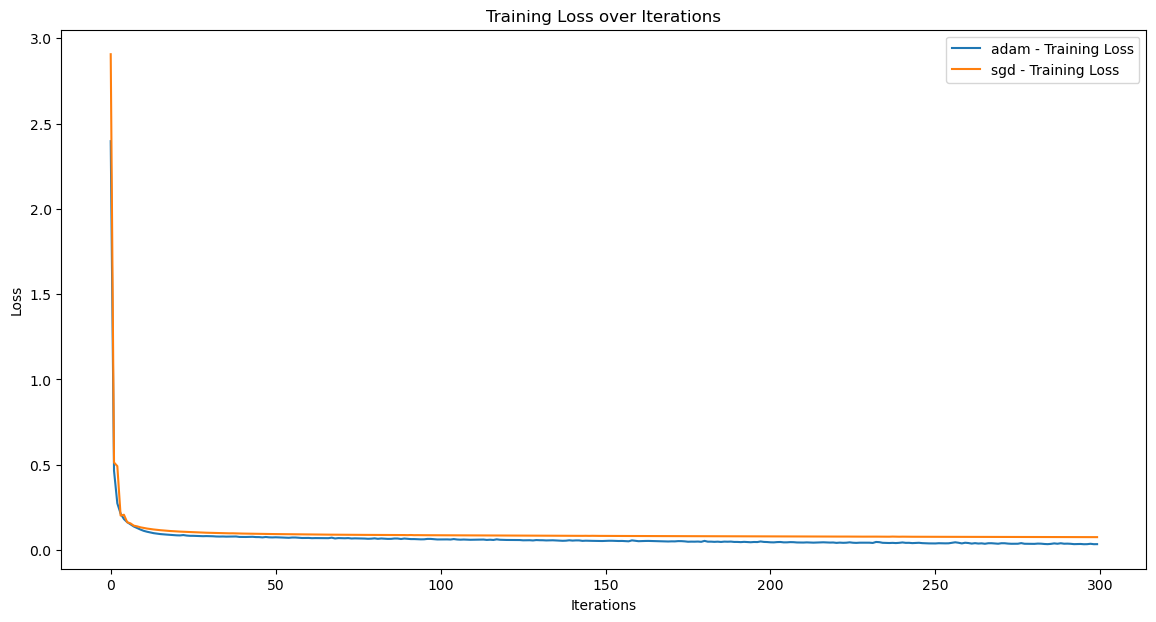

In [ ]:
# Train models and plot learning curves
X = sensor_data_full.drop(columns='CO(GT)')
y = sensor_data_full['CO(GT)']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

imputer = SimpleImputer(missing_values=-999, strategy='mean')
scaler = StandardScaler()
X_train = imputer.fit_transform(X_train)
X_train = scaler.fit_transform(X_train)

X_test = imputer.transform(X_test)
X_test = scaler.transform(X_test)

test_params = [
    {
        'activation': 'relu', 
        'alpha': 0.001, 
        'early_stopping': False, 
        'hidden_layer_sizes': (100, 100), 
        'solver': 'adam',
        'max_iter': 300
    },
    {
        'activation': 'relu', 
        'alpha': 0.001, 
        'early_stopping': False, 
        'hidden_layer_sizes': (100, 100), 
        'learning_rate': 'adaptive', 
        'momentum': 0.95, 
        'solver': 'sgd',
        'max_iter': 300
    },
]

plt.figure(figsize=(14, 7))

for idx, params in enumerate(test_params):
    model = MLPRegressor(**params, random_state=42)
    model.fit(X_train, y_train)

    train_loss = model.loss_curve_

    # Predict and calculate metrics
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_mse = mean_squared_error(y_train, train_pred)
    test_mse = mean_squared_error(y_test, test_pred)

    print(f"Model {idx+1} - Solver: {params['solver']}")
    print(f"Training Set MSE: {train_mse}")
    print(f"Testing Set MSE: {test_mse}")
    print(f"Testing Set R²: {r2_score(y_test, test_pred)}\n")

    plt.plot(train_loss, label=f"{params['solver']} - Training Loss")

plt.xlabel('Iterations')
plt.ylabel('Loss')
plt.title('Training Loss over Iterations')
plt.legend()
plt.show()

# Print final test set performance for both models


## Selected preprocessing and regression pipeline

The final notebook fits the selected mean-imputation / RobustScaler / MLPRegressor pipeline directly. Selection evidence is retained in the non-executable earlier-code appendix below. The original comment about handling noise is an intention, not a demonstrated robustness result.

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.neural_network import MLPRegressor
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
import numpy as np
import matplotlib.pyplot as plt

sensor_data_full = pd.read_excel(DATA_PATH)

X = sensor_data_full.drop(columns='CO(GT)')
y = sensor_data_full['CO(GT)']

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Create a pipeline for preprocessing and model training
pipeline = Pipeline([
    ('imputer', SimpleImputer(missing_values=-999, strategy='mean')),  # Handle missing values
    ('scaler', RobustScaler()),  # Use robust scaling to handle outliers and noise
    ('mlp', MLPRegressor(
        random_state=42,
        max_iter=5000,
        hidden_layer_sizes=(100,),
        activation='relu',
        alpha=0.001,
        solver='adam'
    ))
])

pipeline.fit(X_train, y_train)

# Evaluate the model on the test set
y_pred = pipeline.predict(X_test)
test_mse = mean_squared_error(y_test, y_pred)
test_r2 = r2_score(y_test, y_pred)
print(f"Test Set MSE: {test_mse}")
print(f"Test Set R²: {test_r2}")



Test Set MSE: 0.19032583475222026
Test Set R²: 0.9108300557162875


## Earlier model-selection code (archive; not executable)

The earlier notebook used five-fold GridSearchCV around the complete imputation/scaling/MLP pipeline. This cell searched 48 parameter combinations. Its selected parameters were ReLU, (100,), alpha 0.001 and Adam. The final notebook above hard-codes that selection. The earlier code is reproduced below for provenance, not added to the executable workflow; its saved test MSE/R² match the final notebook. Matching outputs do not establish independent trials.

```python
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.neural_network import MLPRegressor
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
import numpy as np
import matplotlib.pyplot as plt

X = sensor_data_full.drop(columns='CO(GT)')
y = sensor_data_full['CO(GT)']

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Create a pipeline for preprocessing and model training
pipeline = Pipeline([
    ('imputer', SimpleImputer(missing_values=-999, strategy='mean')),  # Handle missing values
    ('scaler', RobustScaler()),  # Use robust scaling to handle outliers and noise
    ('mlp', MLPRegressor(random_state=42, max_iter=5000))
])

# Define parameter grid for GridSearchCV
param_grid = {
    'mlp__hidden_layer_sizes': [(50,), (100,), (50, 50), (100, 100)],
    'mlp__activation': ['relu', 'tanh'],
    'mlp__alpha': [0.0001, 0.001, 0.01],
    'mlp__solver': ['adam', 'sgd']
}

# Perform grid search for hyperparameter tuning
grid_search = GridSearchCV(pipeline, param_grid, scoring='neg_mean_squared_error', cv=5, n_jobs=-1)
grid_search.fit(X_train, y_train)

# Get the best model and its parameters
best_model = grid_search.best_estimator_
best_params = grid_search.best_params_
print(f"Best Parameters: {best_params}")

# Evaluate the model on the test set
y_pred = best_model.predict(X_test)
test_mse = mean_squared_error(y_test, y_pred)
test_r2 = r2_score(y_test, y_pred)
print(f"Test Set MSE: {test_mse}")
print(f"Test Set R²: {test_r2}")
```